In [1]:
import pandas as pd 
import seaborn as sns 
import numpy as np 
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv("df_clean2.csv")

In [3]:
df

,student_id,enrolment_date,city,course,mode,group,pre_score,attendance_pct,final_score,completed,dropped_out,score_improvement,performance_change,enrolment_month,enrolment_day,month_name
0,1,2026-06-01,Ahmedabad,JEE,Offline,treatment,52.7,55.1,74.9,1,0,22.2,Improved,6,1,June
1,2,2026-06-01,Vadodara,NEET,Offline,control,70.3,49.6,75.4,1,0,5.1,Improved,6,1,June
2,3,2026-06-01,Ahmedabad,NEET,Online,treatment,71.6,68.2,75.7,1,0,4.1,Improved,6,1,June
3,4,2026-06-01,Ahmedabad,Class 12,Offline,control,46.0,25.4,50.0,0,1,4.0,Improved,6,1,June
4,5,2026-06-01,Ahmedabad,Class 12,Online,control,69.0,75.2,65.2,1,0,-3.8,Decline,6,1,June
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7895,7896,2026-07-26,Vadodara,NEET,Online,control,26.9,55.8,46.1,0,1,19.2,Improved,7,26,July
7896,7897,2026-07-26,Rajkot,Class 12,Online,control,29.9,23.1,47.8,0,1,17.9,Improved,7,26,July
7897,7898,2026-07-26,Surat,NEET,Offline,treatment,55.9,56.0,66.0,0,1,10.1,Improved,7,26,July
7898,7899,2026-07-26,Vadodara,NEET,Online,treatment,67.1,72.1,75.8,1,0,8.7,Improved,7,26,July


In [6]:
#finding the mean of group 
df.groupby('group')["final_score"].agg(["count", "mean", "median", "std", "min", "max"]
)

,count,mean,median,std,min,max
group,,,,,,
control,3850,63.195221,63.15,11.360947,16.7,99.4
treatment,3867,65.170727,65.20,11.456205,20.2,100.0


In [7]:
#score improvement comparision 
df.groupby('group')['score_improvement'].agg(["count","mean","median","std","min","max"])

,count,mean,median,std,min,max
group,,,,,,
control,3850,5.067467,5.0,8.845937,-26.200000,37.6
treatment,3867,7.125890,7.1,8.926658,-31.133209,35.7


In [8]:
df.groupby("group")["completed"].mean() * 100

group
control      37.012658
treatment    42.000000
Name: completed, dtype: float64

In [9]:
df.groupby("group")["dropped_out"].mean() * 100

group
control      62.987342
treatment    58.000000
Name: dropped_out, dtype: float64

In [11]:
#summary 
group_summary = df.groupby('group').agg(
    total_students=("student_id", "count"),
    avg_pre_score=("pre_score", "mean"),
    avg_final_score=("final_score", "mean"),
    avg_improvement=("score_improvement", "mean"),
    completion_rate=("completed", "mean"),
    dropout_rate=("dropped_out", "mean")
    
)
group_summary["completion_rate"] *= 100
group_summary["dropout_rate"] *= 100

In [12]:
group_summary

,total_students,avg_pre_score,avg_final_score,avg_improvement,completion_rate,dropout_rate
group,,,,,,
control,3950,58.167322,63.195221,5.067467,37.012658,62.987342
treatment,3950,58.063937,65.170727,7.125890,42.000000,58.000000


<h2>Average final score comparison

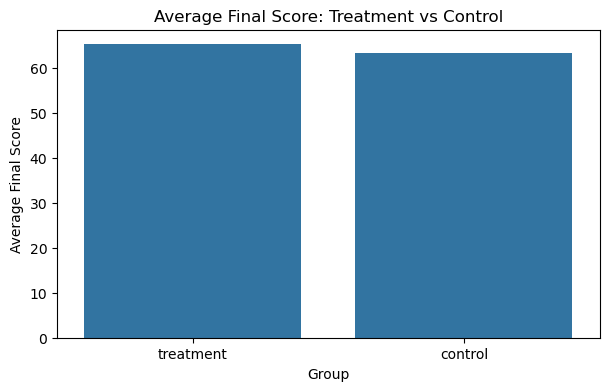

In [16]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=df,
    x="group",
    y="final_score",
    estimator="mean",
    errorbar=None
)

plt.title("Average Final Score: Treatment vs Control")
plt.xlabel("Group")
plt.ylabel("Average Final Score")
plt.show()

<h2>Average improvement comparison

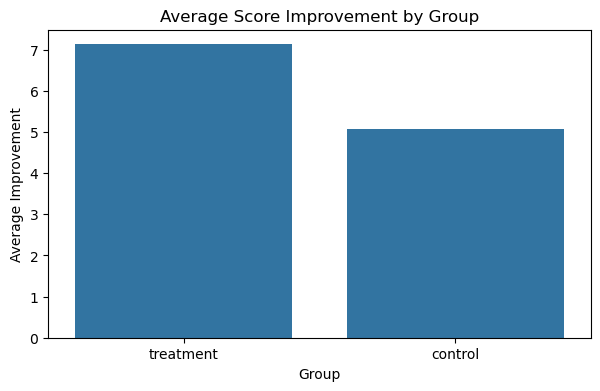

In [17]:
plt.figure(figsize=(7,4))
sns.barplot(
    data=df, 
    x='group', 
    y='score_improvement', 
    estimator='mean', 
    errorbar=None
)

plt.title("Average Score Improvement by Group")
plt.xlabel("Group")
plt.ylabel("Average Improvement")

plt.show()

In [20]:
completion = df.groupby('group')['completed'].mean()*100

In [22]:
completion

group
control      37.012658
treatment    42.000000
Name: completed, dtype: float64

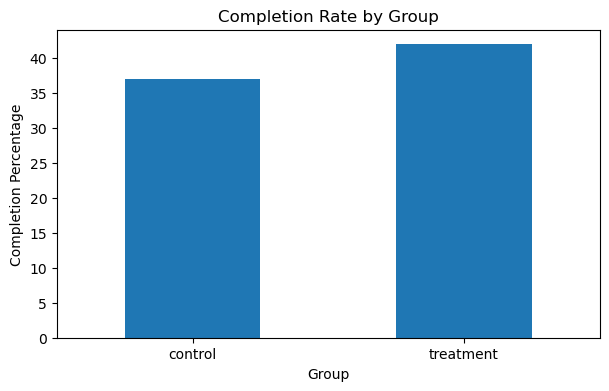

In [23]:
completion.plot(kind = 'bar', figsize=(7,4))
plt.title("Completion Rate by Group")
plt.ylabel("Completion Percentage")
plt.xlabel("Group")
plt.xticks(rotation=0)

plt.show()

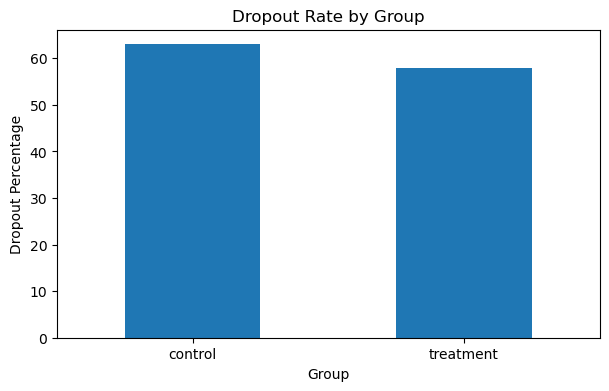

In [25]:
dropout = (
    df.groupby("group")["dropped_out"].mean() * 100
)

dropout.plot(kind="bar", figsize=(7, 4))

plt.title("Dropout Rate by Group")
plt.ylabel("Dropout Percentage")
plt.xlabel("Group")
plt.xticks(rotation=0)

plt.show()

In [27]:
df.groupby("group").agg(
    total_students=("student_id", "count"),
    available_final_scores=("final_score", "count"),
    available_improvements=("score_improvement", "count")
)

,total_students,available_final_scores,available_improvements
group,,,
control,3950,3850,3850
treatment,3950,3867,3867
